In [2]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, GRU, SimpleRNN, Embedding, Reshape, Input, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv('news.csv')
df.head()

,source,title,text,publication_date,rubric,subrubric,tags
0,lenta.ru,Синий богатырь,В 1930-е годы Советский Союз охватила лихорадк...,2020-08-30T00:01:00+03:00,Экономика,Госэкономика,NaN
1,lenta.ru,Загитова согласилась вести «Ледниковый период»,Олимпийская чемпионка по фигурному катанию Ал...,2020-08-31T20:04:00+03:00,Спорт,Зимние виды,NaN
2,lenta.ru,Объяснена опасность однообразного питания,Российский врач-диетолог Римма Мойсенко объясн...,2020-08-31T20:07:00+03:00,Из жизни,Еда,NaN
3,lenta.ru,«Предохраняться? А зачем?»,В 2019 году телеканал «Ю» запустил адаптацию з...,2020-08-30T00:04:00+03:00,Интернет и СМИ,ТВ и радио,NaN
4,lenta.ru,Ефремов систематически употреблял наркотики,Актер Михаил Ефремов систематически употребл...,2020-08-31T18:27:00+03:00,Культура,Кино,NaN


In [6]:
text = ''
for s in df['text'].head(700).values:
    text += s
text

'В 1930-е годы Советский Союз охватила лихорадка — в десятилетие бурной индустриализации повсюду гремели сообщения о новых трудовых подвигах простого народа ради построения коммунизма и светлого будущего. Первым из них стал шахтер из Донбасса  Алексей Стаханов . 85 лет назад он установил рекорд по добыче угля за смену и на следующее утро проснулся знаменитым на весь мир. Его одаривали квартирами и машинами, возили по Союзу, он стал любимцем Сталина, однако в итоге не выдержал славы и спился. Фамилия Стаханова, которая дала название движению трудовиков, превратилась в нарицательную и продолжила существовать отдельно от него. Живая витрина коммунизма — в материале  «Ленты.ру» . История легенды советского труда началась на шахте «Центральная-Ирмино» в Донбассе. К 1935 году советские власти запустили вторую пятилетку и активно проводили политику ускоренной индустриализации, пытаясь по заветам Владимира Ленина догнать и перегнать развитые капиталистические страны, от которых безнадежно отст

In [7]:
import spacy

nlp = spacy.load("ru_core_news_sm")

doc = nlp(text)
filtered_words = [token.text for token in doc if not token.is_stop]
text = " ".join(filtered_words)
text

'1930-е годы Советский Союз охватила лихорадка — десятилетие бурной индустриализации повсюду гремели сообщения новых трудовых подвигах простого народа построения коммунизма светлого будущего . Первым шахтер Донбасса   Алексей Стаханов . 85 лет установил рекорд добыче угля смену следующее утро проснулся знаменитым мир . одаривали квартирами машинами , возили Союзу , любимцем Сталина , итоге выдержал славы спился . Фамилия Стаханова , дала название движению трудовиков , превратилась нарицательную продолжила существовать отдельно . Живая витрина коммунизма — материале   « Ленты.ру » . История легенды советского труда началась шахте « Центральная - Ирмино » Донбассе . 1935 году советские власти запустили вторую пятилетку активно проводили политику ускоренной индустриализации , пытаясь заветам Владимира Ленина догнать перегнать развитые капиталистические страны , безнадежно отстали экономическом плане распада Российской империи . препятствием пути низкая производительность труда советских р

In [8]:
import re

text = re.sub(r'[^а-яА-ЯёЁ .]', '', text)

text = re.sub(r'\s+', ' ', text).strip()
text = text.lower()
text

'е годы советский союз охватила лихорадка десятилетие бурной индустриализации повсюду гремели сообщения новых трудовых подвигах простого народа построения коммунизма светлого будущего . первым шахтер донбасса алексей стаханов . лет установил рекорд добыче угля смену следующее утро проснулся знаменитым мир . одаривали квартирами машинами возили союзу любимцем сталина итоге выдержал славы спился . фамилия стаханова дала название движению трудовиков превратилась нарицательную продолжила существовать отдельно . живая витрина коммунизма материале ленты.ру . история легенды советского труда началась шахте центральная ирмино донбассе . году советские власти запустили вторую пятилетку активно проводили политику ускоренной индустриализации пытаясь заветам владимира ленина догнать перегнать развитые капиталистические страны безнадежно отстали экономическом плане распада российской империи . препятствием пути низкая производительность труда советских рабочих . угольной промышленности повышению ме

# BOW

In [9]:
sentences = [s.strip() for s in text.split('.') if len(s.strip()) > 0]

vectorizer = CountVectorizer(max_features=5000)
X_bow = vectorizer.fit_transform(sentences)
vocab_size = len(vectorizer.vocabulary_)

In [11]:
word_index = vectorizer.vocabulary_
sequences = []
for sentence in sentences:
    sequence = [word_index[word] for word in sentence.split() if word in word_index]
    sequences.append(sequence)

X = []
y = []
for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[:i])
        y.append(seq[i])

max_len = max(len(x) for x in X)
X_padded = np.zeros((len(X), max_len), dtype=np.int32)
for i, seq in enumerate(X):
    X_padded[i, -len(seq):] = seq

y_onehot = np.zeros((len(y), vocab_size))
y_onehot[np.arange(len(y)), y] = 1

X_train, X_test, y_train, y_test = train_test_split(
    X_padded, y_onehot, test_size=0.2, random_state=42
)

In [ ]:
y_onehot[0]

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
y_onehot.shape

(46607, 5000)

In [14]:
def create_rnn_model(model_type='rnn', vocab_size=5000, max_len=10):
    model = Sequential()
    model.add(Embedding(vocab_size, 128, input_length=max_len, mask_zero=True))
    
    if model_type == 'rnn':
        model.add(SimpleRNN(128))
    elif model_type == 'gru':
        model.add(GRU(128))
    elif model_type == 'lstm':
        model.add(LSTM(128))
    
    model.add(Dropout(0.05))
    model.add(Dense(vocab_size, activation='softmax'))
    model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])
    return model

In [24]:
bow_models = {}
for model_type in ['rnn', 'gru', 'lstm']:
    print(f"\nTraining {model_type.upper()} model...")

    early_stopping = EarlyStopping(
        monitor='val_loss',    # Мониторим validation loss
        patience=2,           # Ждем 2 эпохи без улучшения
    )
    
    model = create_rnn_model(model_type, vocab_size, max_len)
    history = model.fit(X_train, y_train,
                       epochs=10,
                       batch_size=32,
                       validation_data=(X_test, y_test), 
                       callbacks=[early_stopping])
    
    y_pred = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_test, axis=1)
    
    accuracy = accuracy_score(y_true_classes, y_pred_classes)
    precision = precision_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    recall = recall_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    f1 = f1_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    
    print(f"{model_type.upper()} Results:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    
    bow_models[model_type] = {
        'model': model,
        'history': history.history,
        'metrics': {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1
        }
    }


Training RNN model...
Epoch 1/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 43s 34ms/step - accuracy: 0.0097 - loss: 8.2698 - val_accuracy: 0.0337 - val_loss: 7.8581
Epoch 2/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 38s 32ms/step - accuracy: 0.0590 - loss: 7.2422 - val_accuracy: 0.0843 - val_loss: 7.4440
Epoch 3/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 38s 33ms/step - accuracy: 0.1483 - loss: 6.0103 - val_accuracy: 0.1233 - val_loss: 7.2836
Epoch 4/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 39s 33ms/step - accuracy: 0.2680 - loss: 4.8394 - val_accuracy: 0.1480 - val_loss: 7.2778
Epoch 5/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 39s 33ms/step - accuracy: 0.4055 - loss: 3.8790 - val_accuracy: 0.1628 - val_loss: 7.3689
Epoch 6/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━ 39s 34ms/step - accuracy: 0.5269 - loss: 3.0832 - val_accuracy: 0.1710 - val_loss: 7.5149
292/292 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
RNN Results:
Accuracy: 0.1710
Precision: 0.1613
Recall: 0.1710
F1-score: 0.1525

Training GRU model...
Epoch 1/10
1166/1166 ━━━━━━━━━━━━━━━━━━━━

In [25]:
def generate_text(model, vectorizer, seed_text, num_words=10):
    word_index = vectorizer.vocabulary_
    index_word = {v: k for k, v in word_index.items()}
    
    current_word = seed_text
    generated_text = [current_word]
    
    for _ in range(num_words):
        sequence = np.array([[word_index.get(current_word, 0)]])
        
        pred = model.predict(sequence, verbose=0)
        predicted_index = np.argmax(pred)
        
        current_word = index_word.get(predicted_index, '')
        generated_text.append(current_word)
        
        if not current_word:
            break
    
    return ' '.join(generated_text)

In [54]:
seed = "повсюду"

for model_type in bow_models:
    print(f"\n{model_type.upper()} generated text:")
    print(generate_text(bow_models[model_type]['model'], vectorizer, seed))


RNN generated text:
повсюду время пандемии коронавируса зафиксировали новых случаев коронавируса зафиксировали новых случаев

GRU generated text:
повсюду году компания вышел свободу президент белоруссии третью неделю проходят акции

LSTM generated text:
повсюду страны заявил эфире телеканала произошел лампас августа белоруссии третью неделю


# N-gramms

In [ ]:
n_gram_length = 6
max_sequence_length = 100

tokenizer = Tokenizer(num_words=5000)  
tokenizer.fit_on_texts([text])
total_words = tokenizer.num_words + 1 

input_sequences = []
for line in text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(n_gram_length, len(token_list)):
        n_gram_sequence = token_list[i-n_gram_length:i+1]
        input_sequences.append(n_gram_sequence)

input_sequences = np.array(pad_sequences(input_sequences, maxlen=n_gram_length+1, padding='post'))
X_ngram, y_ngram = input_sequences[:, :-1], input_sequences[:, -1]  

X_train_ngram, X_test_ngram, y_train_ngram, y_test_ngram = train_test_split(
    X_ngram, y_ngram, test_size=0.2, random_state=42
)

NameError: name 'Tokenizer' is not defined

In [ ]:
X_ngram[0]

array([1149,  379, 4850, 2009, 3700, 2389], dtype=int32)

In [18]:
X_ngram.shape

(55450, 6)

In [57]:
def build_ngram_model(model_type='rnn', total_words=total_words, input_length=n_gram_length):
    model = Sequential()
    model.add(Embedding(total_words, 128, input_length=input_length, mask_zero=True))
    
    if model_type == 'rnn':
        model.add(SimpleRNN(128))
    elif model_type == 'gru':
        model.add(GRU(128))
    elif model_type == 'lstm':
        model.add(LSTM(128))
    
    model.add(Dropout(0.05))
    model.add(Dense(total_words, activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [59]:
ngram_models = {}
for model_type in ['rnn', 'gru', 'lstm']:
    print(f"\nTraining {model_type.upper()} for N-grams...")

    early_stopping = EarlyStopping(
        monitor='val_loss',    # Мониторим validation loss
        patience=2,           # Ждем 2 эпохи без улучшения
    )

    model = build_ngram_model(model_type, total_words, n_gram_length)
    history = model.fit(X_train_ngram, y_train_ngram, 
                       epochs=25, batch_size=32, 
                       validation_data=(X_test_ngram, y_test_ngram), 
                       callbacks=[early_stopping])
    
    y_pred = model.predict(X_test_ngram)
    y_pred_classes = np.argmax(y_pred, axis=1)

    if y_test_ngram.ndim == 1:
        y_true_classes = y_test_ngram  # Если классы уже в виде чисел
    else:
        y_true_classes = np.argmax(y_test_ngram, axis=1)

    accuracy = accuracy_score(y_true_classes, y_pred_classes)
    precision = precision_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    recall = recall_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    f1 = f1_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
    
    print(f"{model_type.upper()} Metrics - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")
    
    ngram_models[model_type] = {
        'model': model,
        'history': history.history,
        'metrics': {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1
        }
    }


Training RNN for N-grams...
Epoch 1/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.0078 - loss: 8.2459 - val_accuracy: 0.0329 - val_loss: 7.8793
Epoch 2/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 36s 26ms/step - accuracy: 0.0487 - loss: 7.2909 - val_accuracy: 0.0737 - val_loss: 7.6058
Epoch 3/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 37s 26ms/step - accuracy: 0.1316 - loss: 6.0092 - val_accuracy: 0.1010 - val_loss: 7.5831
Epoch 4/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 38s 28ms/step - accuracy: 0.2596 - loss: 4.8072 - val_accuracy: 0.1125 - val_loss: 7.7177
Epoch 5/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 44s 32ms/step - accuracy: 0.4181 - loss: 3.7530 - val_accuracy: 0.1208 - val_loss: 7.9375
347/347 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
RNN Metrics - Accuracy: 0.1208, Precision: 0.1028, Recall: 0.1208, F1: 0.1014

Training GRU for N-grams...
Epoch 1/25
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 48s 32ms/step - accuracy: 0.0065 - loss: 8.2417 - val_accuracy: 0.0182 - val_loss: 7.9093
Epoch 2/25
1387/1387 ━━━━━━━━━━

In [65]:
def generate_text(model, tokenizer, seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=n_gram_length, padding='pre')

        predicted = np.argmax(model.predict(token_list), axis=-1)
        
        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break
        seed_text += " " + output_word
    return seed_text

In [67]:
seed_text = "повсюду"

outputs = [generate_text(ngram_models[model_type]['model'], tokenizer, seed_text) for model_type in ngram_models]

for i, model_type in enumerate(ngram_models):
    print(f"\n{model_type.upper()} N-gram model:")
    print(outputs[i])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━

In [68]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    plt.suptitle(title)
    
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.legend()
    
    plt.show()

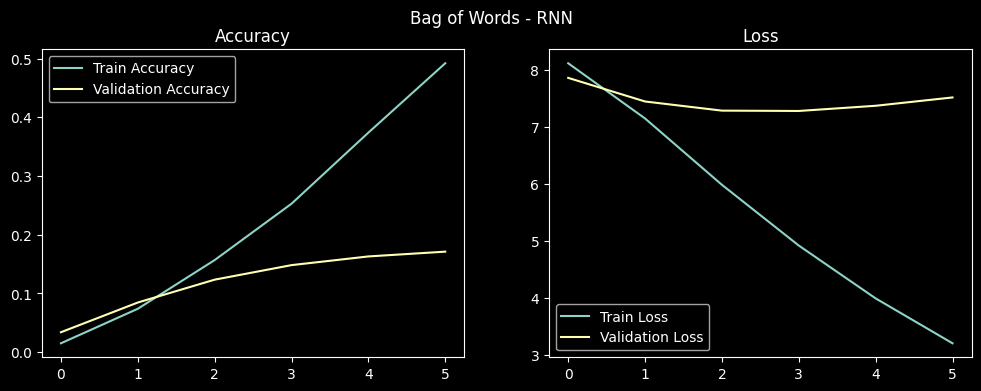

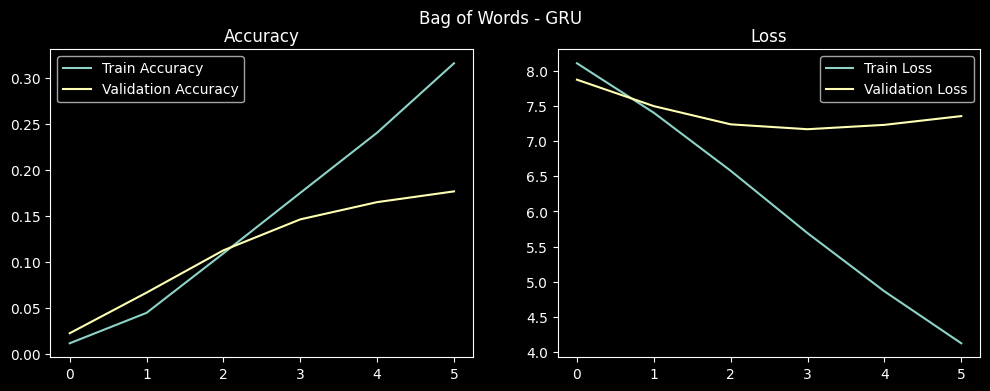

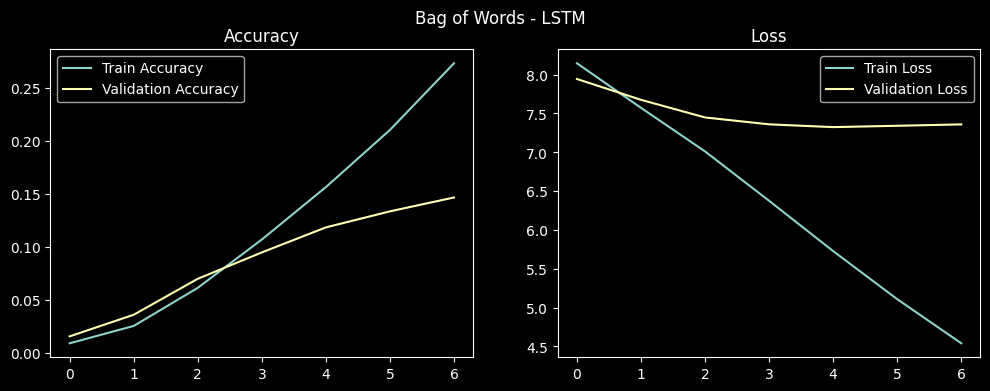

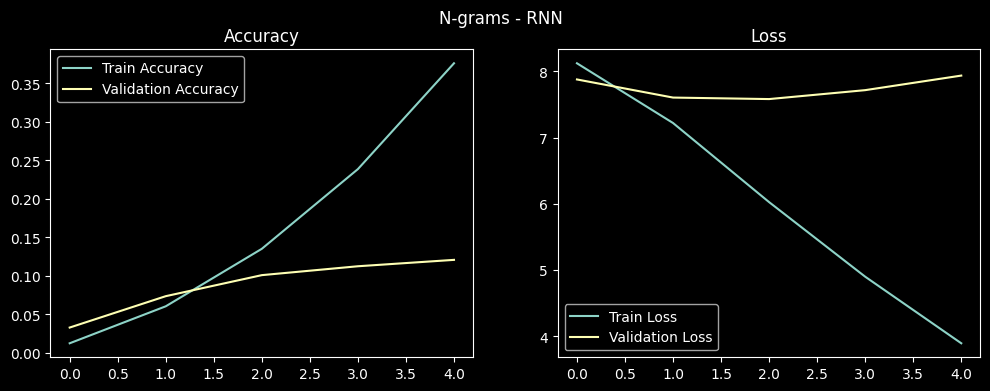

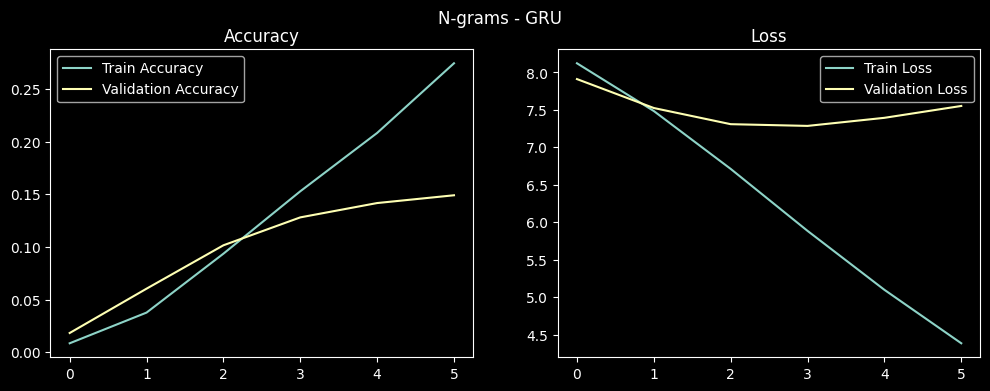

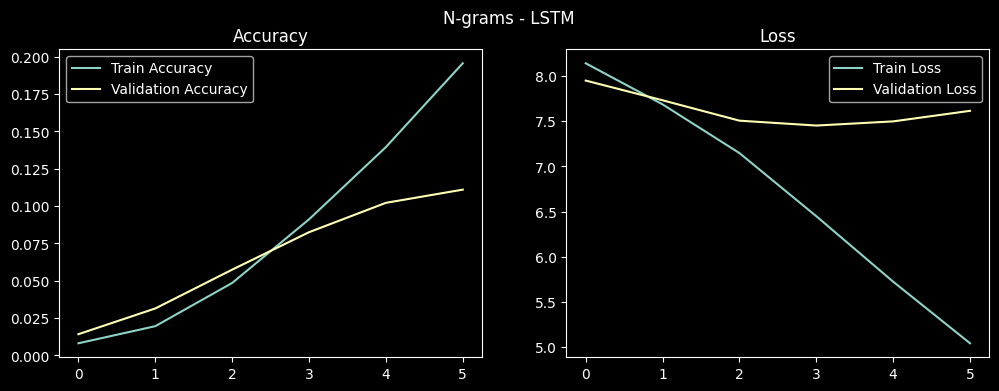

In [69]:
for model_type in bow_models:
    plot_history(bow_models[model_type]['history'], f'Bag of Words - {model_type.upper()}')

for model_type in ngram_models:
    plot_history(ngram_models[model_type]['history'], f'N-grams - {model_type.upper()}')